# Hands-on 21 (Bab 9): Clustering Pola Ruangan dari Data Suhu-Kelembaban

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* (Onno W. Purbo), Bab 9.

Tanpa label, K-Means mencari mode operasi ruangan (sejuk-lembap, hangat-normal, panas-kering);
DBSCAN mencari pola serupa sekaligus menandai titik noise (label -1).

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /home/sandbox/iot-ml-book


## 1. K-Means (uji K=2..5 dengan silhouette score)

=== Silhouette Score untuk beberapa K ===
K=2, silhouette=0.5508
K=3, silhouette=0.4356
K=4, silhouette=0.3770
K=5, silhouette=0.3466

Jumlah data per cluster:
cluster_kmeans
0    1316
1    1445
2    1559

Rata-rata per cluster:
                temperature_c  humidity_pct
cluster_kmeans                             
0                       25.28         67.57
1                       27.93         64.72
2                       22.42         70.60

[SUKSES] outputs/reports/room_kmeans_cluster.csv
[SUKSES] outputs/figures/room_kmeans_scatter.png



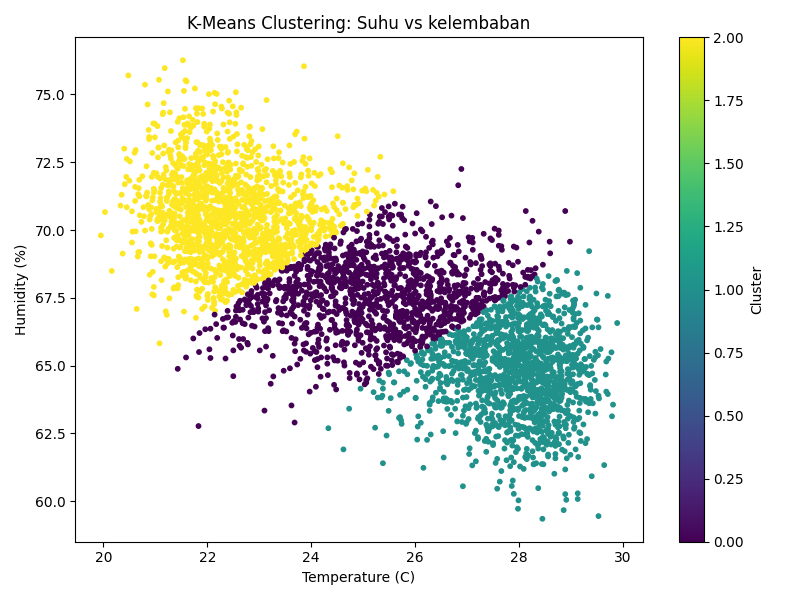

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/cluster_room_kmeans.py"], capture_output=True, text=True)
print(r.stdout)
from IPython.display import Image
Image("outputs/figures/room_kmeans_scatter.png")

## 2. DBSCAN (pola + noise)

=== Hasil DBSCAN ===
cluster_dbscan
-1       7
 0    4313

[INFO] Titik noise (label -1): 7 baris
[SUKSES] outputs/reports/room_dbscan_cluster.csv
[SUKSES] outputs/figures/room_dbscan_scatter.png



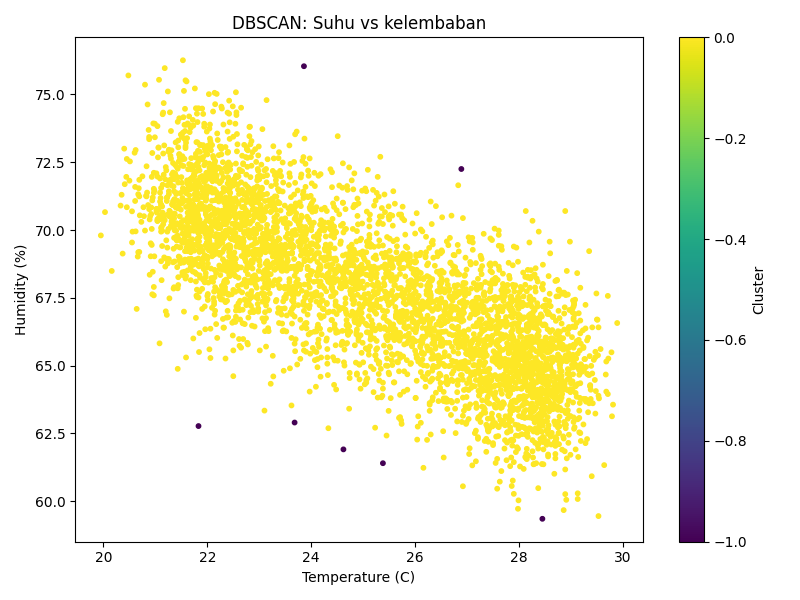

In [3]:
r = subprocess.run([sys.executable, "scripts/cluster_room_dbscan.py"], capture_output=True, text=True)
print(r.stdout)
Image("outputs/figures/room_dbscan_scatter.png")

## Penutup

K-Means K=3 memecah data menjadi tiga mode masuk akal: sejuk-lembap (22.4 C / 70.6%),
hangat-normal (25.3 C / 67.6%), dan panas-kering (27.9 C / 64.7%). Silhouette tertinggi
di K=2 menunjukkan pemisahan paling tegas adalah kondisi sejuk vs hangat. DBSCAN dengan
eps=0.35 melihat data harian yang halus sebagai satu cluster rapat dan menandai 7 titik
sebagai noise. Hasil tersimpan di `outputs/reports/room_kmeans_cluster.csv` dan
`outputs/reports/room_dbscan_cluster.csv`.

## Catatan dari buku: pengamatan, variasi, dan latihan

Bagian berikut disalin dari buku (Hands-on 23 dalam urutan buku) agar dapat dijadikan panduan pengamatan dan latihan mandiri setelah menjalankan notebook ini.

### 10. Insight praktis Hands-on 21

Dari latihan ini, pembaca belajar bahwa:
- K-Means bagus untuk segmentasi cepat,
- DBSCAN bagus untuk cluster + noise,
- dan cluster hasil unsupervised harus tetap ditafsirkan dengan domain knowledge,
bukan dianggap label bisnis otomatis.